# POLARIS Saturated Hydraulic Conductivity (`ksat`) Raster Prep

Downloads, mosaics, clips, and aligns 30 m POLARIS `ksat` GeoTIFF tiles to the exact six-state `EPSG:5070` grid used in `NLCD_raster_prep2.py`.

- **Source**: `http://hydrology.cee.duke.edu/POLARIS/PROPERTIES/v1.0/ksat/`
- **Native units**: `log10(cm/hr)` — bilinear resampling is performed in `log10` space before optional block-wise back-transformation (`10 ** x`) to linear `cm/hr`.

In [2]:
import math
import os
import subprocess
import numpy as np
import requests
import geopandas as gpd
import osmnx as ox
import rasterio
from rasterio.enums import Resampling
from shapely.geometry import box
import matplotlib.pyplot as plt

states = [
    "Ohio",
    "Michigan",
    "Indiana",
    "Pennsylvania",
    "Kentucky",
    "West Virginia",
]

# POLARIS ksat configuration
# Statistics: "mean", "mode", "p50" (median), "p5", "p95"
# Depths (cm): "0_5", "5_15", "15_30", "30_60", "60_100", "100_200"
STAT = "mean"
DEPTH = "0_5"
BASE_URL = f"http://hydrology.cee.duke.edu/POLARIS/PROPERTIES/v1.0/ksat/{STAT}/{DEPTH}"

# Set True to also write a back-transformed linear cm/hr raster (10 ** log10_ksat)
SAVE_LINEAR_CM_HR = True

DST_CRS = "EPSG:5070"
DST_NODATA = -9999.0  # Float32 nodata for continuous ksat

WORK_DIR = "/kaggle/working"
TILE_DIR = os.path.join(WORK_DIR, f"polaris_ksat_{STAT}_{DEPTH}_tiles")
os.makedirs(TILE_DIR, exist_ok=True)


In [3]:
# 1. Build 6-state bounding polygon and lock exact 30m-aligned EPSG:5070 bounds
ox.settings.cache_folder = os.path.join(WORK_DIR, "cache")

region_queries = [f"{state}, USA" for state in states]
regions_gdf = ox.geocode_to_gdf(region_queries)

# Keep WGS84 boundary for 1x1 degree POLARIS tile intersection
boundary_4326 = regions_gdf.to_crs("EPSG:4326").union_all().buffer(0)

# Project to EPSG:5070 BEFORE unioning/buffering so geometry ops happen in meters
regions_5070 = regions_gdf.to_crs(DST_CRS)
master_boundary = regions_5070.union_all().buffer(0)

cutline_path = os.path.join(WORK_DIR, "six_state_cutline_5070.gpkg")
gpd.GeoDataFrame(geometry=[master_boundary], crs=DST_CRS).to_file(
    cutline_path, driver="GPKG"
)

# Exact same 30m-aligned bounding box logic as NLCD_raster_prep2.py
minx, miny, maxx, maxy = master_boundary.bounds
te_bounds = [
    str(int(minx // 30) * 30),
    str(int(miny // 30) * 30),
    str(int((maxx // 30) + 1) * 30),
    str(int((maxy // 30) + 1) * 30),
]
print(f"Locked 30m aligned bounds (EPSG:5070): {te_bounds}")


Locked 30m aligned bounds (EPSG:5070): ['429030', '1513980', '1781880', '2834850']


In [4]:
# 2. Download intersecting 1x1 degree POLARIS ksat GeoTIFF tiles
min_lon, min_lat, max_lon, max_lat = boundary_4326.bounds
lat_range = range(math.floor(min_lat), math.floor(max_lat) + 1)
lon_range = range(math.floor(min_lon), math.floor(max_lon) + 1)

downloaded_tiles = []

for lat in lat_range:
    for lon in lon_range:
        tile_geom = box(lon, lat, lon + 1, lat + 1)
        if not boundary_4326.intersects(tile_geom):
            continue

        fname = f"lat{lat}{lat + 1}_lon{lon}{lon + 1}.tif"
        url = f"{BASE_URL}/{fname}"
        local_path = os.path.join(TILE_DIR, fname)

        if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
            downloaded_tiles.append(local_path)
            continue

        resp = requests.get(url, stream=True, timeout=60)
        if resp.status_code == 200:
            with open(local_path, "wb") as f:
                for chunk in resp.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
            downloaded_tiles.append(local_path)
            print(f"Downloaded {fname}")
        elif resp.status_code == 404:
            print(f"Skipped {fname} (404 - outside CONUS/water)")
        else:
            resp.raise_for_status()

if not downloaded_tiles:
    raise RuntimeError("No POLARIS ksat tiles were downloaded; check network or URL.")

print(f"Total tiles ready for mosaic: {len(downloaded_tiles)}")


Downloaded lat3637_lon-90-89.tif
Downloaded lat3637_lon-89-88.tif
Downloaded lat3637_lon-88-87.tif
Downloaded lat3637_lon-87-86.tif
Downloaded lat3637_lon-86-85.tif
Downloaded lat3637_lon-85-84.tif
Downloaded lat3637_lon-84-83.tif
Downloaded lat3637_lon-83-82.tif
Downloaded lat3738_lon-90-89.tif
Downloaded lat3738_lon-89-88.tif
Downloaded lat3738_lon-88-87.tif
Downloaded lat3738_lon-87-86.tif
Downloaded lat3738_lon-86-85.tif
Downloaded lat3738_lon-85-84.tif
Downloaded lat3738_lon-84-83.tif
Downloaded lat3738_lon-83-82.tif
Downloaded lat3738_lon-82-81.tif
Downloaded lat3738_lon-81-80.tif
Downloaded lat3738_lon-80-79.tif
Downloaded lat3839_lon-89-88.tif
Downloaded lat3839_lon-88-87.tif
Downloaded lat3839_lon-87-86.tif
Downloaded lat3839_lon-86-85.tif
Downloaded lat3839_lon-85-84.tif
Downloaded lat3839_lon-84-83.tif
Downloaded lat3839_lon-83-82.tif
Downloaded lat3839_lon-82-81.tif
Downloaded lat3839_lon-81-80.tif
Downloaded lat3839_lon-80-79.tif
Downloaded lat3839_lon-79-78.tif
Downloaded

In [5]:
# 3. Build VRT mosaic, then clip, reproject, and align in a single GDAL pass (log10 cm/hr)
vrt_path = os.path.join(WORK_DIR, f"polaris_ksat_{STAT}_{DEPTH}.vrt")
out_log10_path = os.path.join(
    WORK_DIR, f"polaris_ksat_{STAT}_{DEPTH}_log10_clipped_reproj.tiff"
)

subprocess.run(
    ["gdalbuildvrt", "-overwrite", vrt_path, *downloaded_tiles],
    check=True,
    capture_output=True,
    text=True,
)

cmd = [
    "gdalwarp",
    "-overwrite",
    "-t_srs", DST_CRS,
    "-te", *te_bounds,           # Exact shared extent with NLCD rasters
    "-tr", "30", "30",           # Exact 30m x 30m resolution
    "-r", "bilinear",            # Continuous interpolation in log10 space
    "-cutline", cutline_path,
    "-dstnodata", str(DST_NODATA),
    "-ot", "Float32",
    "-multi",
    "-wo", "NUM_THREADS=ALL_CPUS",
    "-co", "COMPRESS=LZW",
    "-co", "TILED=YES",
    "-co", "BLOCKXSIZE=512",
    "-co", "BLOCKYSIZE=512",
    vrt_path,
    out_log10_path,
]

try:
    subprocess.run(cmd, check=True, capture_output=True, text=True)
    print(f"Successfully wrote {out_log10_path}")
except subprocess.CalledProcessError as e:
    print("\nGDAL ERROR:")
    print(e.stderr)
    raise

# Clean up temporary cutline GeoPackage and VRT
for tmp in (cutline_path, vrt_path):
    if os.path.exists(tmp):
        os.remove(tmp)


Successfully wrote /kaggle/working/polaris_ksat_mean_0_5_log10_clipped_reproj.tiff


In [6]:
# 4. Optional: block-wise back-transformation from log10(cm/hr) to linear cm/hr
out_linear_path = os.path.join(
    WORK_DIR, f"polaris_ksat_{STAT}_{DEPTH}_cmhr_clipped_reproj.tiff"
)

if SAVE_LINEAR_CM_HR:
    with rasterio.open(out_log10_path) as src:
        profile = src.profile.copy()
        profile.update(
            dtype="float32",
            nodata=DST_NODATA,
            compress="lzw",
            tiled=True,
            blockxsize=512,
            blockysize=512,
        )

        with rasterio.open(out_linear_path, "w", **profile) as dst:
            for _, window in src.block_windows(1):
                block = src.read(1, window=window)
                valid = (block != DST_NODATA) & np.isfinite(block)
                out_block = np.full(block.shape, DST_NODATA, dtype=np.float32)
                out_block[valid] = np.power(10.0, block[valid], dtype=np.float32)
                dst.write(out_block, 1, window=window)

    print(f"Successfully wrote linear cm/hr raster: {out_linear_path}")


Successfully wrote linear cm/hr raster: /kaggle/working/polaris_ksat_mean_0_5_cmhr_clipped_reproj.tiff


POLARIS ksat log10(cm/hr) (mean, 0_5 cm) | shape: (44029, 45095) | CRS: EPSG:5070 | dtype: float32 | nodata: -9999.0
  -> Grid check passed: exact match with /kaggle/input/datasets/maanav0114/ambystoma-sdm-data/land_cover_clipped_reproj.tiff
POLARIS ksat cm/hr        (mean, 0_5 cm) | shape: (44029, 45095) | CRS: EPSG:5070 | dtype: float32 | nodata: -9999.0
  -> Grid check passed: exact match with /kaggle/input/datasets/maanav0114/ambystoma-sdm-data/land_cover_clipped_reproj.tiff


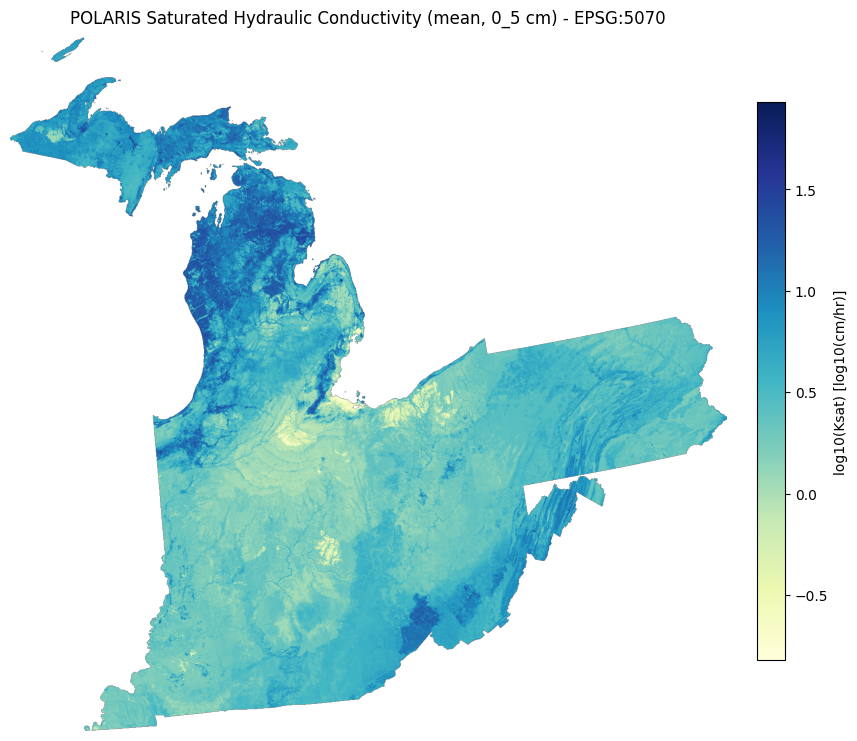

In [8]:
# 5. Verify grid alignment (against NLCD if present) and plot downsampled preview
# ref_nlcd = os.path.join(WORK_DIR, "FctImp_clipped_reproj.tiff")
ref_nlcd = '/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/land_cover_clipped_reproj.tiff'
outputs_to_check = [("log10(cm/hr)", out_log10_path)]
if SAVE_LINEAR_CM_HR and os.path.exists(out_linear_path):
    outputs_to_check.append(("cm/hr", out_linear_path))

for label, path in outputs_to_check:
    with rasterio.open(path) as src:
        print(
            f"POLARIS ksat {label:12s} ({STAT}, {DEPTH} cm) | "
            f"shape: {src.shape} | CRS: {src.crs} | dtype: {src.dtypes[0]} | nodata: {src.nodata}"
        )
        if os.path.exists(ref_nlcd):
            with rasterio.open(ref_nlcd) as ref:
                assert src.shape == ref.shape, f"Shape mismatch: {src.shape} vs {ref.shape}"
                assert src.crs == ref.crs, f"CRS mismatch: {src.crs} vs {ref.crs}"
                assert src.transform == ref.transform, "Affine transform mismatch!"
                print(f"  -> Grid check passed: exact match with {ref_nlcd}")

# Plot in log10(cm/hr) space so orders-of-magnitude permeability differences stay legible
with rasterio.open(out_log10_path) as src:
    max_size = 1500
    scale = min(max_size / src.width, max_size / src.height)
    width = max(1, int(src.width * scale))
    height = max(1, int(src.height * scale))

    image = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.average,
        masked=True,
    )

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(image, cmap="YlGnBu")
plt.colorbar(im, ax=ax, fraction=0.036, pad=0.04, label="log10(Ksat) [log10(cm/hr)]")
ax.set_title(f"POLARIS Saturated Hydraulic Conductivity ({STAT}, {DEPTH} cm) - EPSG:5070")
ax.axis("off")
plt.show()
